[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BASE-Laboratory/OpenImpala/blob/master/tutorials/03_homogenisation_tensor.ipynb)

# Periodic Homogenisation and the $3\times 3$ Effective Diffusivity Tensor

Directional flow-through solves measure only the diagonal responses along the image axes $(x, y, z)$. When a material's principal transport axes are tilted relative to the tomography frame—such as cross-bedded sandstones, woven fibrous gas-diffusion layers, or obliquely aligned flake graphite—an applied gradient along $z$ induces a transverse flux along $x$ or $y$.

Two-scale periodic homogenisation captures the full symmetric positive semi-definite tensor $\mathbf{D}_{\text{eff}} \in \mathbb{R}^{3\times 3}$ by solving three periodic corrector cell problems on the unit cell $Y$:

$$-\nabla \cdot \Bigl(D(\mathbf{x})\bigl(\mathbf{e}_k + \nabla \chi_k\bigr)\Bigr) = 0 \quad \text{in } Y, \qquad D_{\text{eff},ij} = \frac{1}{|Y|} \int_Y D(\mathbf{x})\left(\delta_{ij} + \frac{\partial \chi_j}{\partial x_i}\right)\mathrm{d}V.$$

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip install -q openimpala matplotlib

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import openimpala as oi

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## Recovering Principal Axes on a Tilted Periodic Laminate

Construct a $48^3$ periodic two-phase laminate (`phase=1` with $D_1 = 1.0$, `phase=0` with $D_0 = 0.1$) whose layers are tilted in the $(x, z)$ plane with rational wavevector $\mathbf{q} = (1, 0, -2)$ so that the structure wraps compatibly across all periodic boundaries. Because the sheets tilt at $\theta = \arctan(1/2) \approx 26.6^\circ$ from the $x$-axis toward $+z$, we expect:

- Onsager reciprocity $D_{xz} = D_{zx} > 0$,
- decoupled out-of-plane Voigt transport $D_{yy} = \frac{1}{2}(D_1 + D_0) = 0.55$,
- two in-plane eigenvalues bounded between the Reuss harmonic mean $D_\perp = \frac{2 D_0 D_1}{D_0 + D_1} = 0.1818$ and Voigt arithmetic mean $D_\parallel = 0.55$.

In [3]:
n = 48
iz, iy, ix = np.meshgrid(np.arange(n), np.arange(n), np.arange(n), indexing="ij")
# Period-12 bands along (ix - 2*iz), compatible with n = 48 on the 3-torus
lam = (((ix - 2 * iz) % 12) < 6).astype(np.int32)

tilted = oi.effective_diffusivity(
    lam,
    phase_diffusivities={0: 0.1, 1: 1.0},
    return_fields=True,
)
tilted

Component,Value
D_xx,4.104837e-01
D_yy,5.500000e-01
D_zz,2.395923e-01
D_xy,0.000000e+00
D_xz,1.082553e-01
D_yz,-5.534882e-28
Active VF,1.000000


Diagonalise $\mathbf{D}_{\text{eff}}$ via `np.linalg.eigh` to extract the principal diffusivities and compare the recovered fast eigenvector orientation in $(x, z)$ with the imposed $26.6^\circ$ sheet angle:

In [4]:
D = tilted.tensor
symmetry_err = np.max(np.abs(D - D.T))

eigvals, eigvecs = np.linalg.eigh(D)
xz_weights = eigvecs[0, :] ** 2 + eigvecs[2, :] ** 2
fast_idx = int(np.argmax(xz_weights * eigvals))
v_fast = eigvecs[:, fast_idx]
if v_fast[0] < 0:
    v_fast = -v_fast
theta_recovered = np.degrees(np.arctan2(v_fast[2], v_fast[0]))

print(f"Max |D - D^T|:          {symmetry_err:.2e}")
print(f"Principal eigenvalues:  {np.round(eigvals, 4)}")
print(f"Recovered sheet angle:  {theta_recovered:.2f} deg (imposed arctan(1/2) = {np.degrees(np.arctan(0.5)):.2f} deg)")

Max |D - D^T|:          1.02e-13
Principal eigenvalues:  [0.1871 0.463  0.55  ]
Recovered sheet angle:  25.86 deg (imposed arctan(1/2) = 26.57 deg)


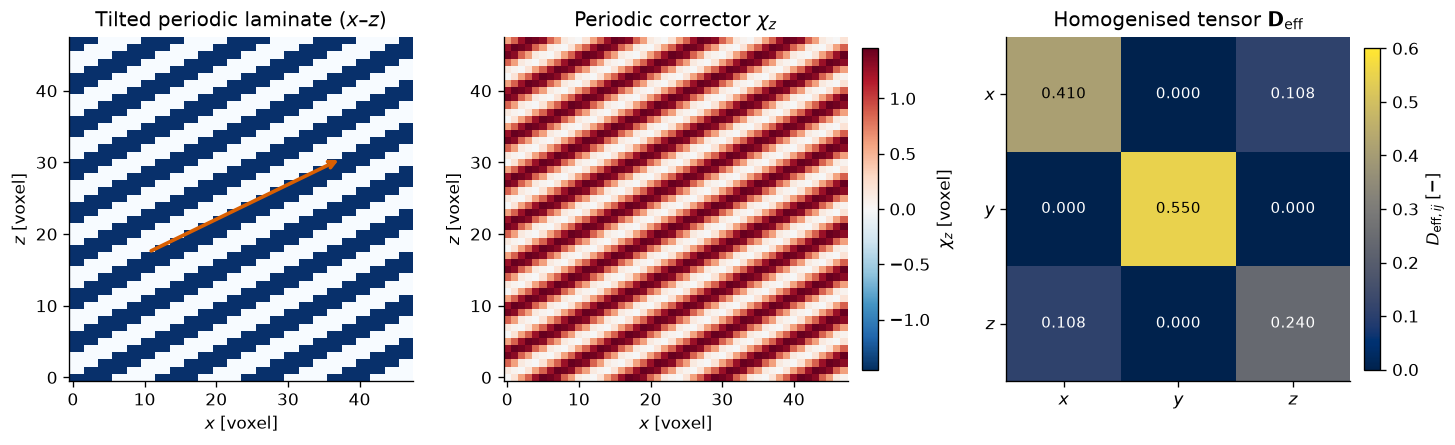

In [5]:
chi_z = tilted.corrector_fields["z"]
mid_y = n // 2

fig, axes = plt.subplots(1, 3, figsize=(12.2, 3.6), layout="constrained")
fig.get_layout_engine().set(w_pad=0.14)

axes[0].imshow(lam[:, mid_y, :], origin="lower", cmap="Blues")
c0 = n / 2.0
axes[0].annotate(
    "",
    xy=(c0 + 15 * v_fast[0], c0 + 15 * v_fast[2]),
    xytext=(c0 - 15 * v_fast[0], c0 - 15 * v_fast[2]),
    arrowprops={"arrowstyle": "->", "color": "#d95f02", "lw": 2.2},
)
axes[0].set_title(r"Tilted periodic laminate ($x$–$z$)")
axes[0].set_xlabel(r"$x$ [voxel]")
axes[0].set_ylabel(r"$z$ [voxel]")

vmax = np.max(np.abs(chi_z[:, mid_y, :]))
im_chi = axes[1].imshow(
    chi_z[:, mid_y, :], origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax
)
axes[1].set_title(r"Periodic corrector $\chi_z$")
axes[1].set_xlabel(r"$x$ [voxel]")
axes[1].set_ylabel(r"$z$ [voxel]")
fig.colorbar(im_chi, ax=axes[1], fraction=0.046, pad=0.04, label=r"$\chi_z$ [voxel]")

im_D = axes[2].imshow(D, cmap="cividis", vmin=0.0, vmax=0.6)
axes[2].set_xticks([0, 1, 2], [r"$x$", r"$y$", r"$z$"])
axes[2].set_yticks([0, 1, 2], [r"$x$", r"$y$", r"$z$"])
axes[2].set_title(r"Homogenised tensor $\mathbf{D}_{\mathrm{eff}}$")
for r_idx in range(3):
    for c_idx in range(3):
        val = 0.0 if abs(D[r_idx, c_idx]) < 5e-4 else D[r_idx, c_idx]
        color = "white" if val < 0.3 else "black"
        axes[2].text(c_idx, r_idx, f"{val:.3f}", ha="center", va="center", color=color, fontsize=9)
fig.colorbar(im_D, ax=axes[2], fraction=0.046, pad=0.04, label=r"$D_{\mathrm{eff},ij}\;[-]$")

plt.show()

## Periodic Homogenisation vs. Dirichlet Flow-Through on Tomographic Data

On a non-periodic finite subvolume cropped from a tomogram, periodic homogenisation wraps opposing faces onto the 3-torus whereas Dirichlet flow-through seals the four lateral faces ($\nabla \phi \cdot \mathbf{n} = 0$). On a sufficiently representative volume the two estimates agree closely along all three axes, with minor differences attributable to artificial boundary re-connections on the periodic wrap.

In [6]:
cubic = oi.datasets.two_phase_cubic()
deff_hom = oi.effective_diffusivity(cubic, phase=1)
flow = oi.tortuosity_all(cubic, phase=1)

print("Axis | Periodic D_eff,ii | Flow-through D_eff")
print("-----+-------------------+-------------------")
for idx, axis in enumerate(("x", "y", "z")):
    d_per = deff_hom.tensor[idx, idx]
    d_dir = flow[axis].effective_diffusivity
    print(f"  {axis.upper()}  |      {d_per:.5f}      |      {d_dir:.5f}")

deff_hom

Axis | Periodic D_eff,ii | Flow-through D_eff
-----+-------------------+-------------------
  X  |      0.12062      |      0.11994
  Y  |      0.11723      |      0.11787
  Z  |      0.11702      |      0.11685


Component,Value
D_xx,1.206226e-01
D_yy,1.172347e-01
D_zz,1.170170e-01
D_xy,-3.815853e-06
D_xz,2.447695e-03
D_yz,-5.905263e-04
Active VF,0.399326


## References

1. G. Allaire, *Homogenization and two-scale convergence*, SIAM J. Math. Anal. **23**(6), 1482–1518 (1992).
2. J. Le Houx, M. Osenberg, I. Manke, and D. Kramer, *Statistical estimation of effective diffusivity in porous media*, Transp. Porous Media **150**, 71–88 (2023).